# PW8 - Logistic Regression

**Team:** Noé Berdoz, Michael Strefeler

Our starting levels, the time spent per exercise and the bonus request are in the preamble of `ex1-logistic-regression-stud.ipynb`.

# Exercise 2 - Optional - Classification on MNIST

Using the SciKit Learn toolkit, train a multi-class logistic regression on the MNIST problem and compare the performances with the KNN of PW2.

For the “daring” ones, implement a multi-class version based on your own implementation and run it against MNIST data.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

plt.rcParams['figure.figsize'] = (10.0, 10.0)
plt.rcParams['image.interpolation'] = 'nearest'
plt.rcParams['image.cmap'] = 'gray'

In [2]:
train = pd.read_csv('mnist_train.csv')
X_train = train.drop('label', axis=1).values.reshape(-1,28,28)
y_train = train['label'].values

test = pd.read_csv('mnist_test.csv')
X_test = test.drop('label', axis=1).values.reshape(-1,28,28)
y_test = test['label'].values

In [3]:
print('Training data shape: ', X_train.shape)
print('Training labels shape: ', y_train.shape)
print('Test data shape: ', X_test.shape)
print('Test labels shape: ', y_test.shape)

Training data shape:  (60000, 28, 28)
Training labels shape:  (60000,)
Test data shape:  (10000, 28, 28)
Test labels shape:  (10000,)


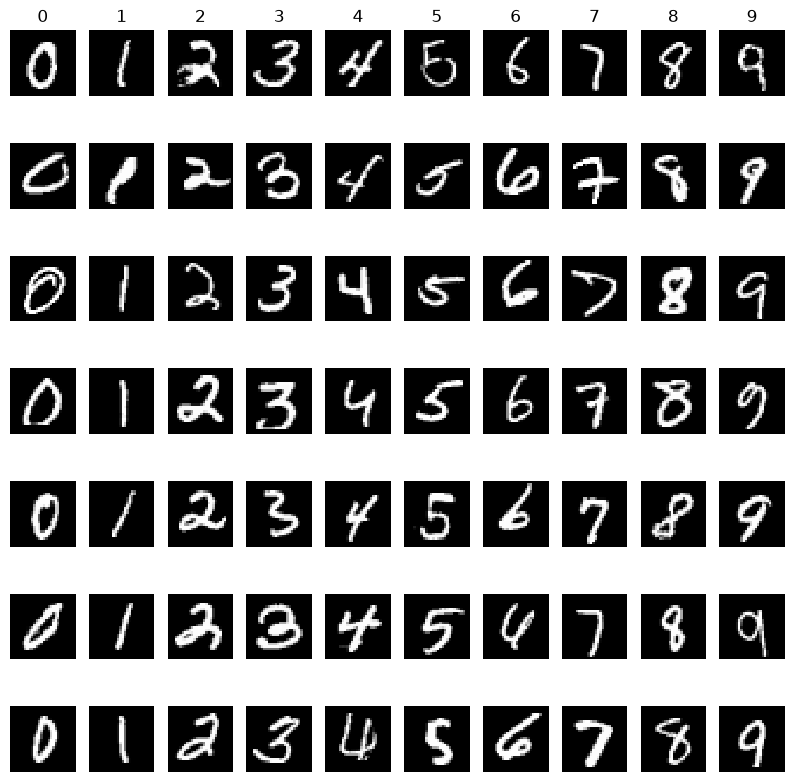

In [4]:
classes = ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9']
num_classes = len(classes)
samples_per_class = 7
for y, cls in enumerate(classes): # y and cls takes values from 0-9
    idxs = np.flatnonzero(y_train == y) # gets the indices of samples that corresponds to class y
    idxs = np.random.choice(idxs, samples_per_class, replace=False) # picks randomly samples_per_class indices
    for i, idx in enumerate(idxs):
        plt_idx = i * num_classes + y + 1   # determines the sub-plot index
        plt.subplot(samples_per_class, num_classes, plt_idx)
        plt.imshow(X_train[idx].astype('uint8'))
        plt.axis('off')
        if i == 0:
            plt.title(cls)
plt.show()

In [5]:
# TODO: train and test this data using logistic regression, you can use scikit-learn.
# You can subsample the data for training, because the set is large.
# You may need to put the data back to 1D.

In [6]:
import time

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, classification_report
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

In [7]:
# Flatten the images to 1D vectors of 28*28 = 784 pixels (new names, so the cell can be re-run safely)
X_train_flat = X_train.reshape(X_train.shape[0], -1)
X_test_flat = X_test.reshape(X_test.shape[0], -1)
print(X_train_flat.shape, X_test_flat.shape)

(60000, 784) (10000, 784)


### Choosing the regularization strength by cross-validation

We use the same protocol as for the KNN in PW2, so that the two models can be compared:

1. choose the hyperparameter by 5-fold cross-validation on the first 5000 training images (for KNN it was $k$, here it is $C$, the inverse of the regularization strength),
2. retrain with the best value on the full training set (60000 images),
3. evaluate on the full test set (10000 images).

The model is a `StandardScaler` followed by a `LogisticRegression` with the default L2 penalty and the `lbfgs` solver, which uses a multinomial (softmax) model for multi-class problems. Putting the scaler in a pipeline means it is fitted only on the training folds during cross-validation, so no information from the validation fold leaks into it.

In [8]:
num_training = 5000
X_sub = X_train_flat[:num_training]
y_sub = y_train[:num_training]

num_folds = 5
C_choices = [1e-4, 1e-3, 3e-3, 1e-2, 3e-2, 1e-1, 1]

C_to_accuracies = {}
for C in C_choices:
    model = make_pipeline(StandardScaler(), LogisticRegression(C=C, max_iter=2000))
    C_to_accuracies[C] = cross_val_score(model, X_sub, y_sub, cv=num_folds, scoring="accuracy")

for C in C_choices:
    accs = C_to_accuracies[C]
    print(f"C = {C:<7g} accuracy = {accs.mean():.4f} +/- {accs.std():.4f}  (folds: {np.round(accs, 3)})")

C = 0.0001  accuracy = 0.8230 +/- 0.0113  (folds: [0.807 0.812 0.836 0.83  0.83 ])
C = 0.001   accuracy = 0.8824 +/- 0.0160  (folds: [0.864 0.865 0.888 0.906 0.889])
C = 0.003   accuracy = 0.8970 +/- 0.0150  (folds: [0.884 0.877 0.904 0.919 0.901])
C = 0.01    accuracy = 0.9002 +/- 0.0175  (folds: [0.887 0.874 0.905 0.922 0.913])
C = 0.03    accuracy = 0.8980 +/- 0.0173  (folds: [0.883 0.874 0.902 0.921 0.91 ])
C = 0.1     accuracy = 0.8928 +/- 0.0112  (folds: [0.882 0.881 0.89  0.91  0.901])
C = 1       accuracy = 0.8814 +/- 0.0115  (folds: [0.872 0.868 0.877 0.897 0.893])


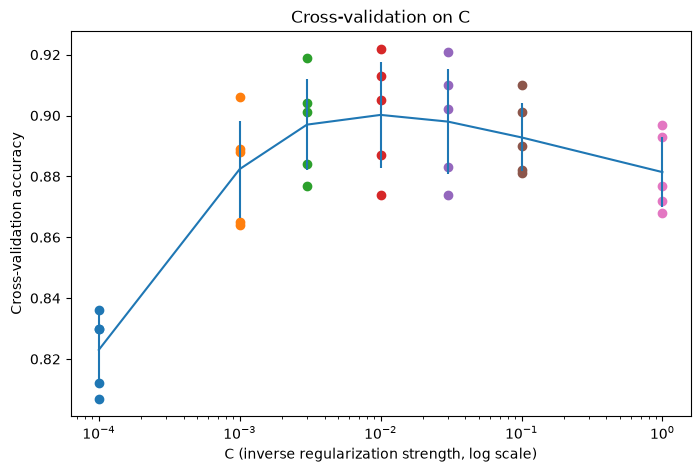

Best C: 0.01


In [9]:
# Same plot as for k in PW2: raw fold accuracies and mean +/- std
plt.figure(figsize=(8, 5))
for C in C_choices:
    plt.scatter([C] * num_folds, C_to_accuracies[C])

accuracies_mean = np.array([C_to_accuracies[C].mean() for C in C_choices])
accuracies_std = np.array([C_to_accuracies[C].std() for C in C_choices])
plt.errorbar(C_choices, accuracies_mean, yerr=accuracies_std)
plt.xscale("log")
plt.title("Cross-validation on C")
plt.xlabel("C (inverse regularization strength, log scale)")
plt.ylabel("Cross-validation accuracy")
plt.show()

best_C = C_choices[int(np.argmax(accuracies_mean))]
print(f"Best C: {best_C:g}")

### Training on the full training set and evaluating on the test set

In [10]:
clf = make_pipeline(StandardScaler(), LogisticRegression(C=best_C, max_iter=2000))

tic = time.time()
clf.fit(X_train_flat, y_train)
train_time = time.time() - tic

tic = time.time()
y_test_pred = clf.predict(X_test_flat)
predict_time = time.time() - tic

num_correct = np.sum(y_test_pred == y_test)
num_test = X_test_flat.shape[0]
accuracy = float(num_correct) / num_test
print(f"Got {int(num_correct)} / {num_test} correct => accuracy: {accuracy}")
print(f"Training time: {train_time:.1f} s, prediction time for {num_test} images: {predict_time:.3f} s")

Got 9261 / 10000 correct => accuracy: 0.9261
Training time: 15.3 s, prediction time for 10000 images: 0.062 s


In [11]:
print(classification_report(y_test, y_test_pred, digits=4))

              precision    recall  f1-score   support

           0     0.9533    0.9796    0.9663       980
           1     0.9628    0.9797    0.9712      1135
           2     0.9373    0.8983    0.9174      1032
           3     0.9030    0.9129    0.9079      1010
           4     0.9341    0.9379    0.9360       982
           5     0.9041    0.8666    0.8849       892
           6     0.9372    0.9509    0.9440       958
           7     0.9250    0.9241    0.9246      1028
           8     0.8774    0.8891    0.8832       974
           9     0.9181    0.9108    0.9144      1009

    accuracy                         0.9261     10000
   macro avg     0.9252    0.9250    0.9250     10000
weighted avg     0.9260    0.9261    0.9259     10000



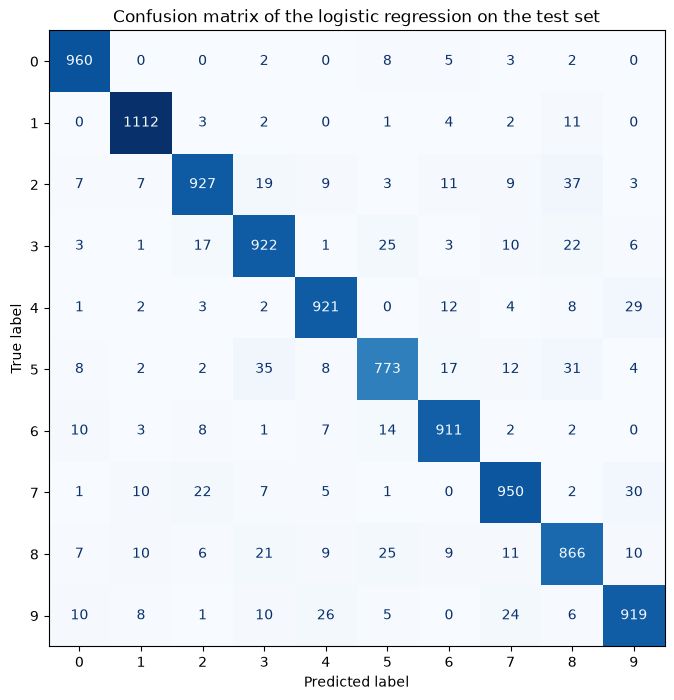

In [12]:
fig, ax = plt.subplots(figsize=(8, 8))
ConfusionMatrixDisplay.from_predictions(y_test, y_test_pred, ax=ax, cmap="Blues", colorbar=False)
ax.set_title("Confusion matrix of the logistic regression on the test set")
plt.show()

### Discussion

Test performance: after retraining on the full 60000 images, the model gets **92.61%** accuracy on the 10000 test images. This is higher than the cross-validation score because it has 12 times more training data. Macro and weighted precision, recall and F1 are all about 0.925, so the classes are handled fairly evenly.

Confusion matrix: the largest errors are between digits with similar shapes, like 2 and 8.

Training and prediction time: training on the 60000 images takes about 13 seconds, and predicting the 10000 test images takes less than 0.1 seconds, since prediction is just one matrix product with a 784 x 10 weight matrix.

KNN Comparison:
- Cross-validation: KNN (k=3) averages about 92.9%, logistic regression (C=0.01) about 90.0%.
- Test accuracy: KNN gets 97.05%, logistic regression 92.61%.
- Prediction cost: logistic regression needs one matrix product, while KNN computes the distance from each test image to all 60000 training images.